In [32]:
#standard library imports
import os
import cv2
import glob
import torch
import numpy as np
import torchvision
from tqdm.auto import tqdm
from torch.utils.data.dataset import Dataset
from torch.utils.data.dataloader import DataLoader
import torchvision.transforms as transforms
from PIL import Image
import matplotlib.pyplot as plt
import yaml
from torch.optim import Adam
from torchvision.utils import make_grid
#DCGAN imports
import sys
sys.path.append("../")
from model.dcgan import Generator, Discriminator
from dataset.mnist_dataset import MnistDataset
from dataset.celeb_dataset import CelebDataset
from torch.utils.data import DataLoader
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

- Lets train DC GANs for CelebA dataset. You can choose any other dataset following the instruction in the readme file. 
- We have provided the code and config file for three dataset, i.e., MNIST, MNIST_coloured and CelebA. 

In [33]:
path2_config = "../config/celeb.yaml"
with open(path2_config, 'r') as file:
        try:
            config = yaml.safe_load(file)
        except yaml.YAMLError as exc:
            print(exc)

dataset_config = config['dataset_params']
model_config = config['model_params']
train_config = config['train_params']
print("Dataset config: ", dataset_config)
print("Model config: ", model_config)
print("Train config: ", train_config)


Dataset config:  {'im_path': 'img_align_celeba', 'im_ext': 'jpg', 'im_channels': 3, 'im_size': 64, 'name': 'celeb'}
Model config:  {'latent_dim': 100, 'generator_channels': [1024, 512, 256, 128], 'generator_kernels': [4, 4, 4, 4, 4], 'generator_strides': [2, 2, 2, 2, 2], 'generator_paddings': [0, 1, 1, 1, 1], 'generator_output_paddings': [0, 0, 0, 0, 0], 'discriminator_channels': [128, 256, 512, 1024], 'discriminator_kernels': [4, 4, 4, 4, 4], 'discriminator_strides': [2, 2, 2, 2, 2], 'discriminator_paddings': [1, 1, 1, 1, 0]}
Train config:  {'task_name': 'task_celeb', 'batch_size': 64, 'num_epochs': 4, 'num_samples': 100, 'num_grid_rows': 10, 'save_sample_steps': 200, 'lr': 0.0005, 'ckpt_name': 'celeb_ckpt.pth'}


#### Dataset and Dataloader

In [34]:
im_dataset = CelebDataset(split='train',
                                im_path="../data/"+dataset_config['im_path']+'/',
                                im_size=dataset_config['im_size'],
                                im_channels=dataset_config['im_channels'],
                                im_ext=dataset_config['im_ext'])
Celeb_loader = DataLoader(im_dataset, batch_size=train_config['batch_size'], shuffle=True)

Found 202599 images


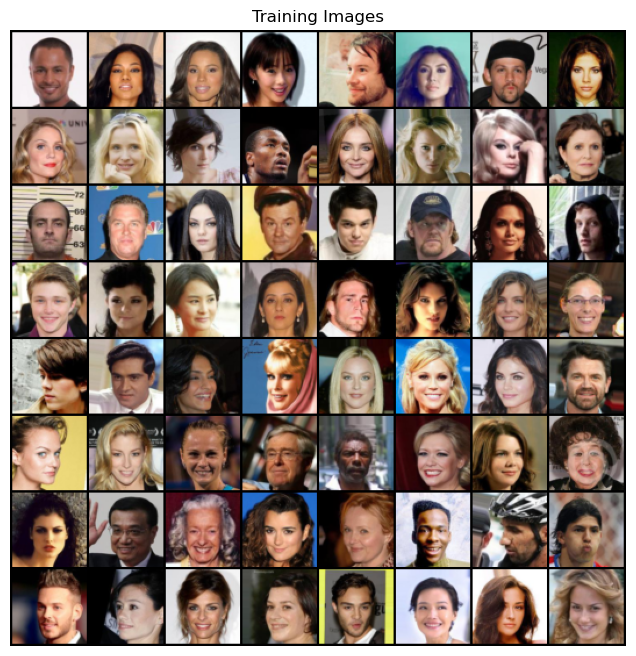

In [35]:
# Plot some training images
real_batch = next(iter(Celeb_loader))
plt.figure(figsize=(8,8))
plt.axis("off")
plt.title("Training Images")
plt.imshow(np.transpose(torchvision.utils.make_grid(real_batch.to(device)[:64], padding=2, normalize=True).cpu(),(1,2,0)))


#### Model

In [36]:
generator = Generator(latent_dim=model_config['latent_dim'],
                        im_size=dataset_config['im_size'],
                        im_channels=dataset_config['im_channels'],
                        conv_channels=model_config['generator_channels'],
                        kernels=model_config['generator_kernels'],
                        strides=model_config['generator_strides'],
                        paddings=model_config['generator_paddings'],
                        output_paddings=model_config['generator_output_paddings']).to(device)

discriminator = Discriminator(im_size=dataset_config['im_size'],
                                im_channels=dataset_config['im_channels'],
                                conv_channels=model_config['discriminator_channels'],
                                kernels=model_config['discriminator_kernels'],
                                strides=model_config['discriminator_strides'],
                                paddings=model_config['discriminator_paddings']).to(device)
generator.train();
discriminator.train();


In [37]:
print(generator)
print(discriminator)

Generator(
  (layers): ModuleList(
    (0): Sequential(
      (0): ConvTranspose2d(100, 1024, kernel_size=(4, 4), stride=(2, 2), bias=False)
      (1): BatchNorm2d(1024, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
    )
    (1): Sequential(
      (0): ConvTranspose2d(1024, 512, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
    )
    (2): Sequential(
      (0): ConvTranspose2d(512, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
    )
    (3): Sequential(
      (0): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
    )
    (4): Sequential(
      (0)

#### Training

In [38]:
optimizer_generator = Adam(generator.parameters(), lr=train_config['lr'], betas=(0.5, 0.999))
optimizer_discriminator = Adam(discriminator.parameters(), lr=train_config['lr'], betas=(0.5, 0.999))
criterion = torch.nn.BCEWithLogitsLoss()

In [39]:
def infer(generated_sample_count, generator, train_config, model_config):
    r"""
    Method to save the generated samples
    :param generated_sample_count: Filename to save the output with
    :param generator: Generator model with trained parameters
    :param train_config: Training configuration picked up from yaml
    :param model_config: Model configuration picked up from yaml
    """
    
    with torch.no_grad():
        fake_im_noise = torch.randn((train_config['num_samples'], model_config['latent_dim']), device=device)
        fake_ims = generator(fake_im_noise)
        fake_ims = (fake_ims + 1) / 2
        grid = make_grid(fake_ims, nrow=train_config['num_grid_rows'])
        img = torchvision.transforms.ToPILImage()(grid)
        if not os.path.exists(os.path.join(train_config['task_name'], 'samples')):
            os.mkdir(os.path.join(train_config['task_name'], 'samples'))
        img.save(os.path.join(train_config['task_name'], 'samples', '{}.png'.format(generated_sample_count)))

In [40]:
# Run training
steps = 0
generated_sample_count = 0

for epoch_idx in range(train_config['num_epochs']):
    generator_losses = []
    discriminator_losses = []
    mean_real_dis_preds = []
    mean_fake_dis_preds = []
    for im in tqdm(Celeb_loader):
        real_ims = im.float().to(device)
        batch_size = real_ims.shape[0]
        
        # Optimize Discriminator
        optimizer_discriminator.zero_grad()
        fake_im_noise = torch.randn((batch_size, model_config['latent_dim']), device=device)
        fake_ims = generator(fake_im_noise)
        real_label = torch.ones((batch_size, 1), device=device)
        fake_label = torch.zeros((batch_size, 1), device=device)
        
        disc_real_pred = discriminator(real_ims)
        disc_fake_pred = discriminator(fake_ims.detach())
        disc_real_loss = criterion(disc_real_pred.reshape(-1), real_label.reshape(-1))
        mean_real_dis_preds.append(torch.nn.Sigmoid()(disc_real_pred).mean().item())
        
        disc_fake_loss = criterion(disc_fake_pred.reshape(-1), fake_label.reshape(-1))
        mean_fake_dis_preds.append(torch.nn.Sigmoid()(disc_fake_pred).mean().item())
        disc_loss = (disc_real_loss + disc_fake_loss) / 2
        disc_loss.backward()
        optimizer_discriminator.step()
        ########################
        
        # Optimize Generator
        optimizer_generator.zero_grad()
        fake_im_noise = torch.randn((batch_size, model_config['latent_dim']), device=device)
        fake_ims = generator(fake_im_noise)
        disc_fake_pred = discriminator(fake_ims)
        gen_fake_loss = criterion(disc_fake_pred.reshape(-1), real_label.reshape(-1))
        gen_fake_loss.backward()
        optimizer_generator.step()
        ########################
        
        generator_losses.append(gen_fake_loss.item())
        discriminator_losses.append(disc_loss.item())

         # Save samples
        if steps % train_config['save_sample_steps'] == 0:
                generator.eval()
                infer(generated_sample_count, generator,
                      train_config, model_config)
                generated_sample_count += 1
                generator.train()
            #############
        steps += 1
        print('Finished epoch:{} | Generator Loss : {:.4f} | Discriminator Loss : {:.4f} | '
              'Discriminator real pred : {:.4f} | Discriminator fake pred : {:.4f}'.format(
            epoch_idx + 1,
            np.mean(generator_losses),
            np.mean(discriminator_losses),
            np.mean(mean_real_dis_preds),
            np.mean(mean_fake_dis_preds),
        ))


  0%|          | 0/3166 [00:00<?, ?it/s]

Finished epoch:1 | Generator Loss : 5.8084 | Discriminator Loss : 0.7180 | Discriminator real pred : 0.4498 | Discriminator fake pred : 0.4582
Finished epoch:1 | Generator Loss : 11.7341 | Discriminator Loss : 1.9869 | Discriminator real pred : 0.7248 | Discriminator fake pred : 0.7283
Finished epoch:1 | Generator Loss : 11.3648 | Discriminator Loss : 1.5579 | Discriminator real pred : 0.6712 | Discriminator fake pred : 0.4855
Finished epoch:1 | Generator Loss : 12.8572 | Discriminator Loss : 1.2229 | Discriminator real pred : 0.7411 | Discriminator fake pred : 0.4316
Finished epoch:1 | Generator Loss : 13.3453 | Discriminator Loss : 1.0030 | Discriminator real pred : 0.7726 | Discriminator fake pred : 0.3453
Finished epoch:1 | Generator Loss : 13.2299 | Discriminator Loss : 0.8572 | Discriminator real pred : 0.7937 | Discriminator fake pred : 0.2877
Finished epoch:1 | Generator Loss : 12.5650 | Discriminator Loss : 0.7501 | Discriminator real pred : 0.8129 | Discriminator fake pred : 

  0%|          | 0/3166 [00:00<?, ?it/s]

Finished epoch:2 | Generator Loss : 1.9813 | Discriminator Loss : 0.1388 | Discriminator real pred : 0.9174 | Discriminator fake pred : 0.1512
Finished epoch:2 | Generator Loss : 3.7081 | Discriminator Loss : 0.2578 | Discriminator real pred : 0.9210 | Discriminator fake pred : 0.2779
Finished epoch:2 | Generator Loss : 3.2091 | Discriminator Loss : 0.3521 | Discriminator real pred : 0.7652 | Discriminator fake pred : 0.1898
Finished epoch:2 | Generator Loss : 3.0036 | Discriminator Loss : 0.3208 | Discriminator real pred : 0.8047 | Discriminator fake pred : 0.2112
Finished epoch:2 | Generator Loss : 3.2230 | Discriminator Loss : 0.3050 | Discriminator real pred : 0.8268 | Discriminator fake pred : 0.2207
Finished epoch:2 | Generator Loss : 3.0509 | Discriminator Loss : 0.2890 | Discriminator real pred : 0.8107 | Discriminator fake pred : 0.1915
Finished epoch:2 | Generator Loss : 3.0828 | Discriminator Loss : 0.2706 | Discriminator real pred : 0.8305 | Discriminator fake pred : 0.1947

  0%|          | 0/3166 [00:00<?, ?it/s]

Finished epoch:3 | Generator Loss : 6.0978 | Discriminator Loss : 0.1674 | Discriminator real pred : 0.9649 | Discriminator fake pred : 0.1862
Finished epoch:3 | Generator Loss : 5.3209 | Discriminator Loss : 0.1498 | Discriminator real pred : 0.8949 | Discriminator fake pred : 0.0987
Finished epoch:3 | Generator Loss : 4.3516 | Discriminator Loss : 0.1471 | Discriminator real pred : 0.8922 | Discriminator fake pred : 0.0961
Finished epoch:3 | Generator Loss : 5.0533 | Discriminator Loss : 0.1557 | Discriminator real pred : 0.9162 | Discriminator fake pred : 0.1368
Finished epoch:3 | Generator Loss : 5.1844 | Discriminator Loss : 0.1494 | Discriminator real pred : 0.9007 | Discriminator fake pred : 0.1102
Finished epoch:3 | Generator Loss : 5.0176 | Discriminator Loss : 0.1346 | Discriminator real pred : 0.9040 | Discriminator fake pred : 0.0945
Finished epoch:3 | Generator Loss : 4.8685 | Discriminator Loss : 0.1259 | Discriminator real pred : 0.9136 | Discriminator fake pred : 0.0953

  0%|          | 0/3166 [00:00<?, ?it/s]

Finished epoch:4 | Generator Loss : 3.7244 | Discriminator Loss : 0.2638 | Discriminator real pred : 0.7170 | Discriminator fake pred : 0.0373
Finished epoch:4 | Generator Loss : 3.1753 | Discriminator Loss : 0.1864 | Discriminator real pred : 0.8226 | Discriminator fake pred : 0.0723
Finished epoch:4 | Generator Loss : 4.1642 | Discriminator Loss : 0.2268 | Discriminator real pred : 0.8686 | Discriminator fake pred : 0.1321
Finished epoch:4 | Generator Loss : 4.2534 | Discriminator Loss : 0.2326 | Discriminator real pred : 0.8368 | Discriminator fake pred : 0.1190
Finished epoch:4 | Generator Loss : 4.3130 | Discriminator Loss : 0.1987 | Discriminator real pred : 0.8630 | Discriminator fake pred : 0.1095
Finished epoch:4 | Generator Loss : 4.2469 | Discriminator Loss : 0.1784 | Discriminator real pred : 0.8758 | Discriminator fake pred : 0.0974
Finished epoch:4 | Generator Loss : 4.1729 | Discriminator Loss : 0.1686 | Discriminator real pred : 0.8831 | Discriminator fake pred : 0.0971

In [46]:
img_list = os.listdir('/home/akansh-i2sc/Desktop/ExplainableAI/DCGAN-Pytorch/notebooks/task_celeb/samples')
len(img_list)

64

Animation size has reached 21540605 bytes, exceeding the limit of 20971520.0. If you're sure you want a larger animation embedded, set the animation.embed_limit rc parameter to a larger value (in MB). This and further frames will be dropped.


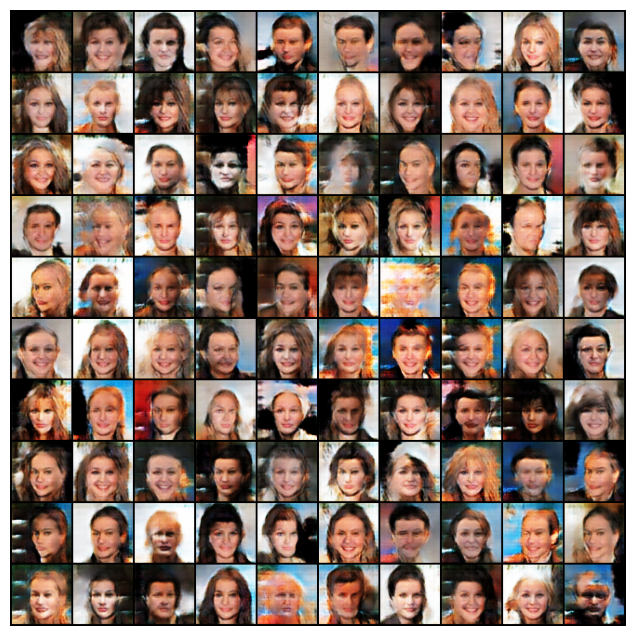

In [47]:
import matplotlib.animation as animation
from IPython.display import HTML
fig = plt.figure(figsize=(8,8))
plt.axis("off")

img_list = os.listdir('./task_celeb/samples/')
img_list.sort()
#selecting only 200 images with step of 10
ims = [[plt.imshow(Image.open('task_celeb/samples/' + str(i)), animated=True)] for i in img_list]
ani = animation.ArtistAnimation(fig, ims, interval=1000, repeat_delay=1000, blit=True)
HTML(ani.to_jshtml())

In [ ]:
with torch.no_grad():
    generator.eval()
    infer(generated_sample_count, generator)
    generated_sample_count += 1
    generator.train()
out = plt.imread("/home/akansh-i2sc/Desktop/ExplainableAI/DCGAN-Pytorch/notebooks/samples/0.png")
plt.figure(figsize=(10,10))
plt.imshow(out)
plt.axis('off')